# London Underground Entries and Exits: Distributions by Time of Day and Station Type

An exploratory analysis of hourly exit counts at 268 London Underground stations, using Python (pandas, matplotlib, SciPy). The goal is to practise reading distributions through histograms and summary statistics, and to see how daily travel patterns differ between types of station.

Based on a university coursework notebook (Statistics for AI and Data Science). The write-up, interpretation and code changes are my own.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Overview
 A few concrete questions of the data and answer each with a suitable plot:

What does the daily profile of entries and exits look like across London Underground?
Is the profile of a single station similar to the network profile?
How do entries and exites relate hour by hour at different kinds of station (interchange, termini, work, shopping)?

## 2. Data
 Two datasets provided in the lecture was generated by Transport for London which record hourly entries and exits per station on a typical weekday (the exact day is not given, but it is not a weekend).

The system closes between 2am and 5am, therefore, each day has 21 hourly columns, from H05 (the hour starting around 5am) to H01 (ending around 1am).

In [7]:
entries = pd.read_csv('../../dataFiles/hourlyEntries.csv', index_col='Station')
exits   = pd.read_csv('../../dataFiles/hourlyExits.csv',   index_col='Station')
exits.shape   # (268, 21)

(268, 21)

## 3. Findings

### 3.1 Network-wide exits by hour
Summing each hourly column gives the overall daily profile.

<Axes: >

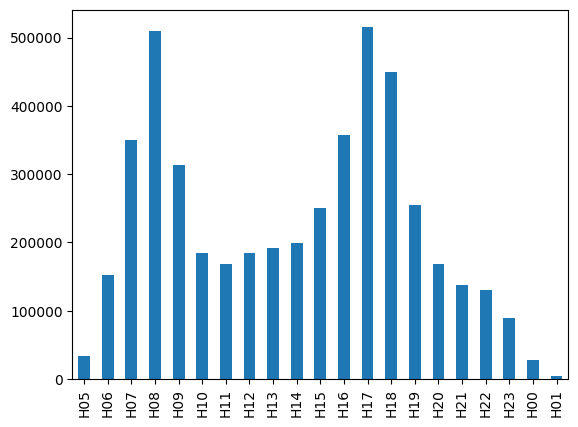

In [13]:
x_sm_en = entries.sum()
x_sm_en.plot(kind='bar')

<Axes: >

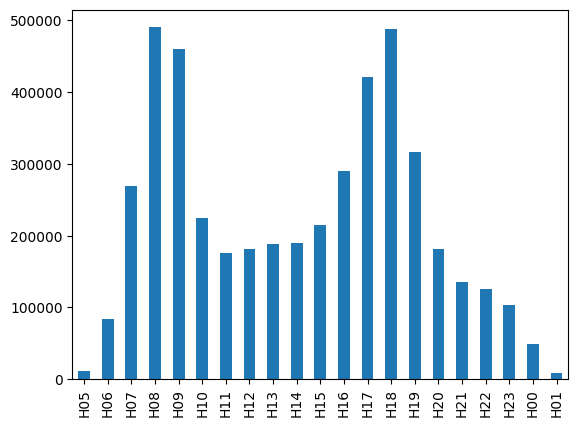

In [8]:
x_sm = exits.sum()
x_sm.plot(kind='bar')


* The profile has two peaks: a morning peak at H08–H09 (about 490k and 460k exits) and an evening peak at H17–H18 (about 420k and 490k).
* Midday is a plateau of roughly 175k–190k exits per hour; the first and last hours of service are close to empty.
* The two peaks are almost the same height (H08 ≈ H18 across the network). My reading is that the network is roughly closed: most people who exit in the morning travel back in the evening.
* Total exits are about 4.6 million per day, or roughly 220k per hour averaged over the 21 operating hours (all figures read from the notebook output, approximate).

A caution about the median. x_sm.median() returns a number, but it is the median of 21 bar heights, not the median time of day. The bars are counts, so the median has to be weighted by them: find the first hour at which the cumulative share of exits passes 50%.

In [9]:
print(x_sm.mean())                           # average exits per operating hour

cum = x_sm.cumsum() / x_sm.sum()
print(cum[cum >= 0.5].index[0])              # median hour -> H15 (about 49% of exits happen before 15:00)

# weighted mean time of day; H00 and H01 are mapped to 24 and 25 so the clock keeps counting after midnight
hours = np.array([(int(c[1:]) - 5) % 24 + 5 for c in exits.columns])
print(np.average(hours, weights=x_sm.values))   # about 14 (hour-start convention)

219434.2857142857
H15
14.063655243353038


### 3.2 Mean versus median across stations

Next I compare, for each hour, the mean and the median of exits across the 268 stations.

Text(0, 0.5, 'Exits')

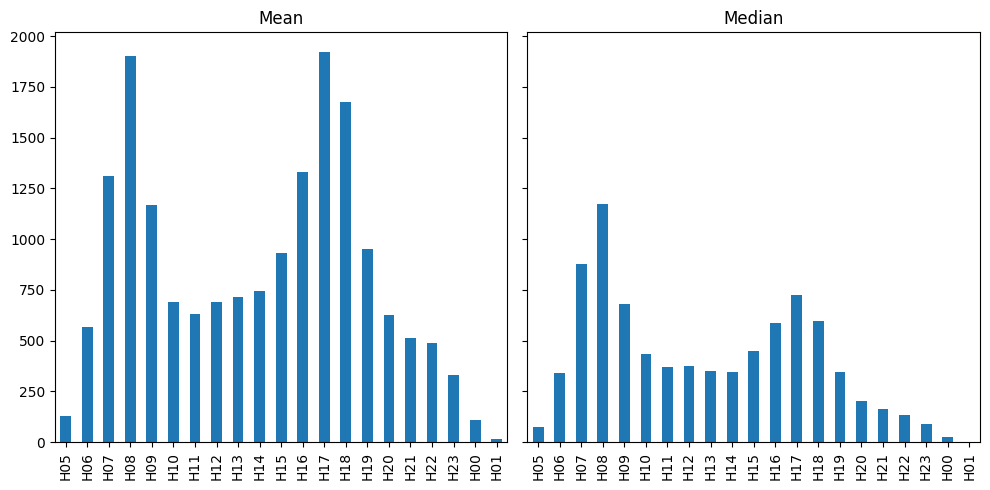

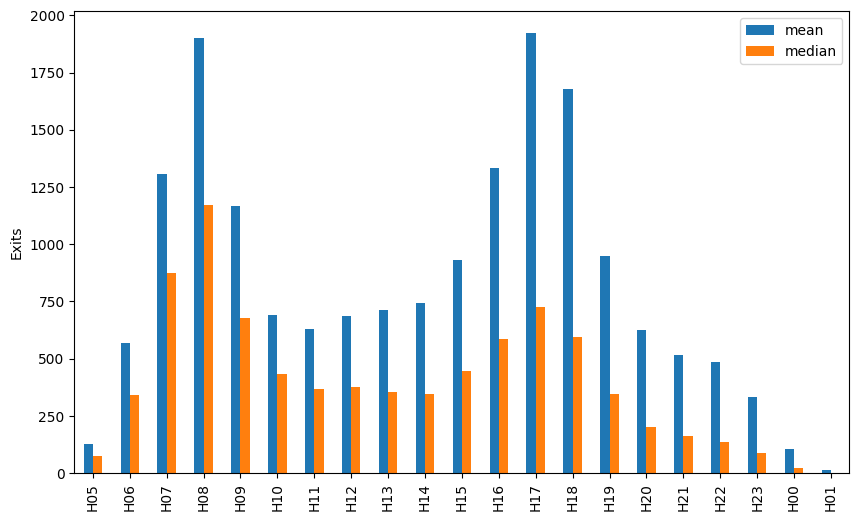

In [14]:
x_mean_en, x_median_en = entries.mean(), entries.median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
x_mean_en.plot(kind='bar', ax=ax1, title='Mean')
x_median_en.plot(kind='bar', ax=ax2, title='Median')
plt.tight_layout()

compare = pd.concat([x_mean_en, x_median_en], axis=1, keys=['mean', 'median'])
compare.plot(kind='bar', figsize=(10, 6))
plt.ylabel('Exits')

Text(0, 0.5, 'Exits')

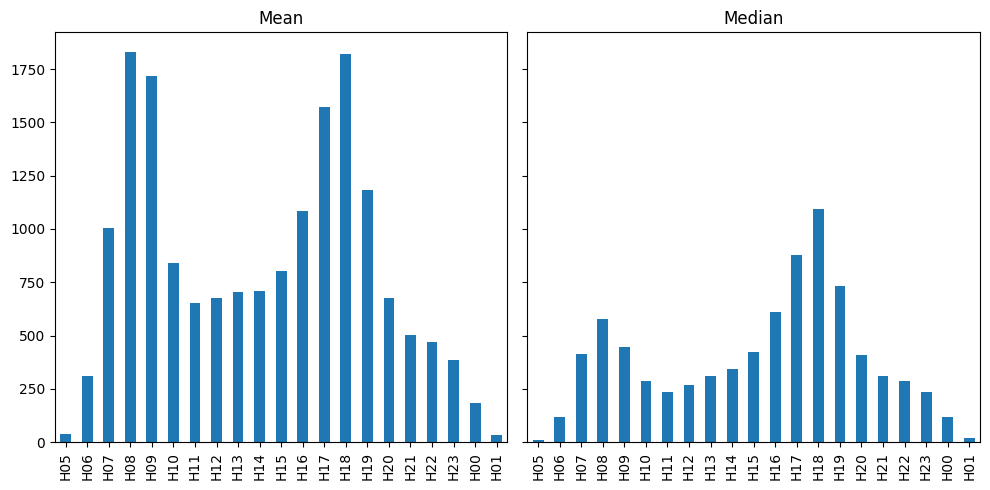

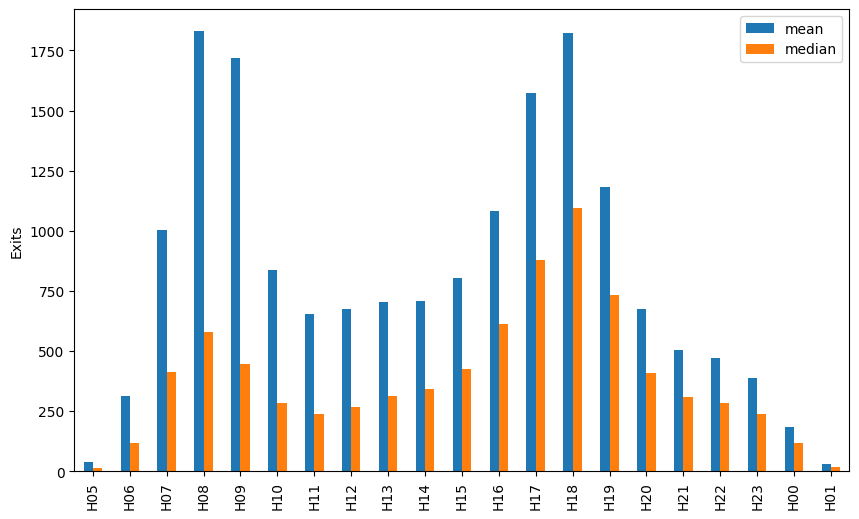

In [10]:
x_mean, x_median = exits.mean(), exits.median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
x_mean.plot(kind='bar', ax=ax1, title='Mean')
x_median.plot(kind='bar', ax=ax2, title='Median')
plt.tight_layout()

compare = pd.concat([x_mean, x_median], axis=1, keys=['mean', 'median'])
compare.plot(kind='bar', figsize=(10, 6))
plt.ylabel('Exits')

* The mean is far above the median in the morning peak: at H08 the mean is about 1,830 exits per station, the median is 579, and the busiest station has 27,069.
* That gap means the distribution across stations is strongly right-skewed: a few very large stations account for much of the traffic, so the mean describes the network total better than it describes a typical station.
* The gap is smaller in the evening (H18: mean about 1,820, median 1,094), which suggests exits are spread more evenly across stations at that time.

### 3.3 A single station: Waterloo

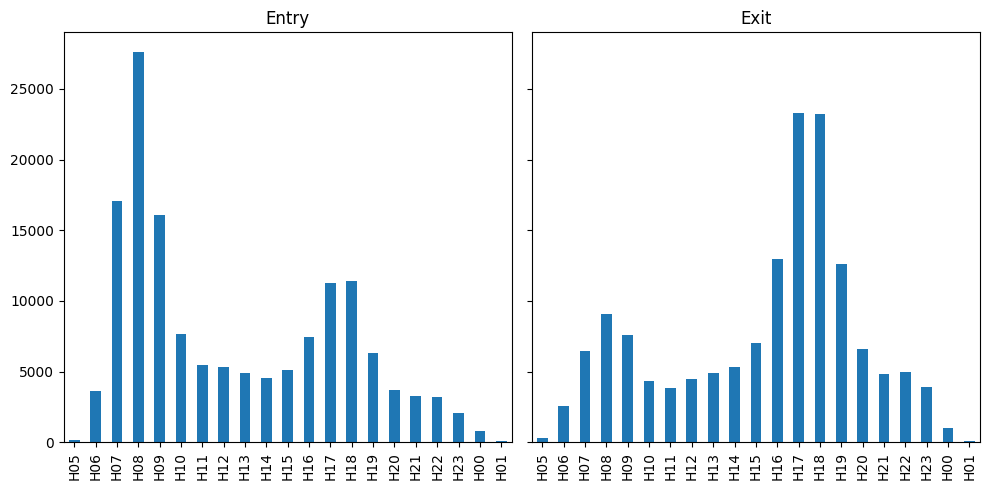

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
entries.loc['Waterloo'].plot(kind='bar', ax=ax1, title='Entry')
exits.loc['Waterloo'].plot(kind='bar', ax=ax2, title='Exit')
plt.tight_layout()

<Axes: >

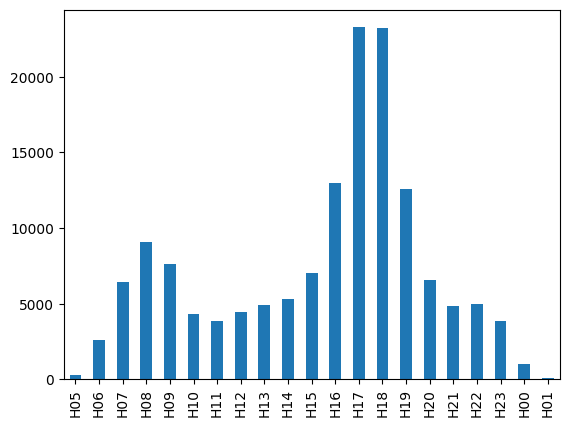

In [11]:
exits.loc['Waterloo'].plot(kind='bar')


* Waterloo is also two-peaked, but unlike the network total the peaks are not equal: the evening peak (about 23k exits at H17–H18) is more than twice the morning peak (about 9k at H08).
* So an individual station can be strongly lopsided even though the network profile is balanced. A plausible reason is that Waterloo is a mainline terminus, so many evening passengers leave the Underground to catch trains home. I have not tested this explanation.

### 3.4 Entries versus exits by station type
For each hour I plot a station's entries against its exits. Each point is one hour, coloured by time of day, and I compare four hand-picked stations in each of four groups.

| Group | Stations |
|---|---|
| Interchange (mainline link) | Euston, London Bridge, Paddington, Liverpool Street |
| Residential / outer | Balham, Barking, Clapham South, Wimbledon |
| Business district | Aldgate, Blackfriars, Canary Wharf, Bank & Monument |
| Shopping / leisure | Bond Street, Green Park, Tottenham Court Road, Oxford Circus |

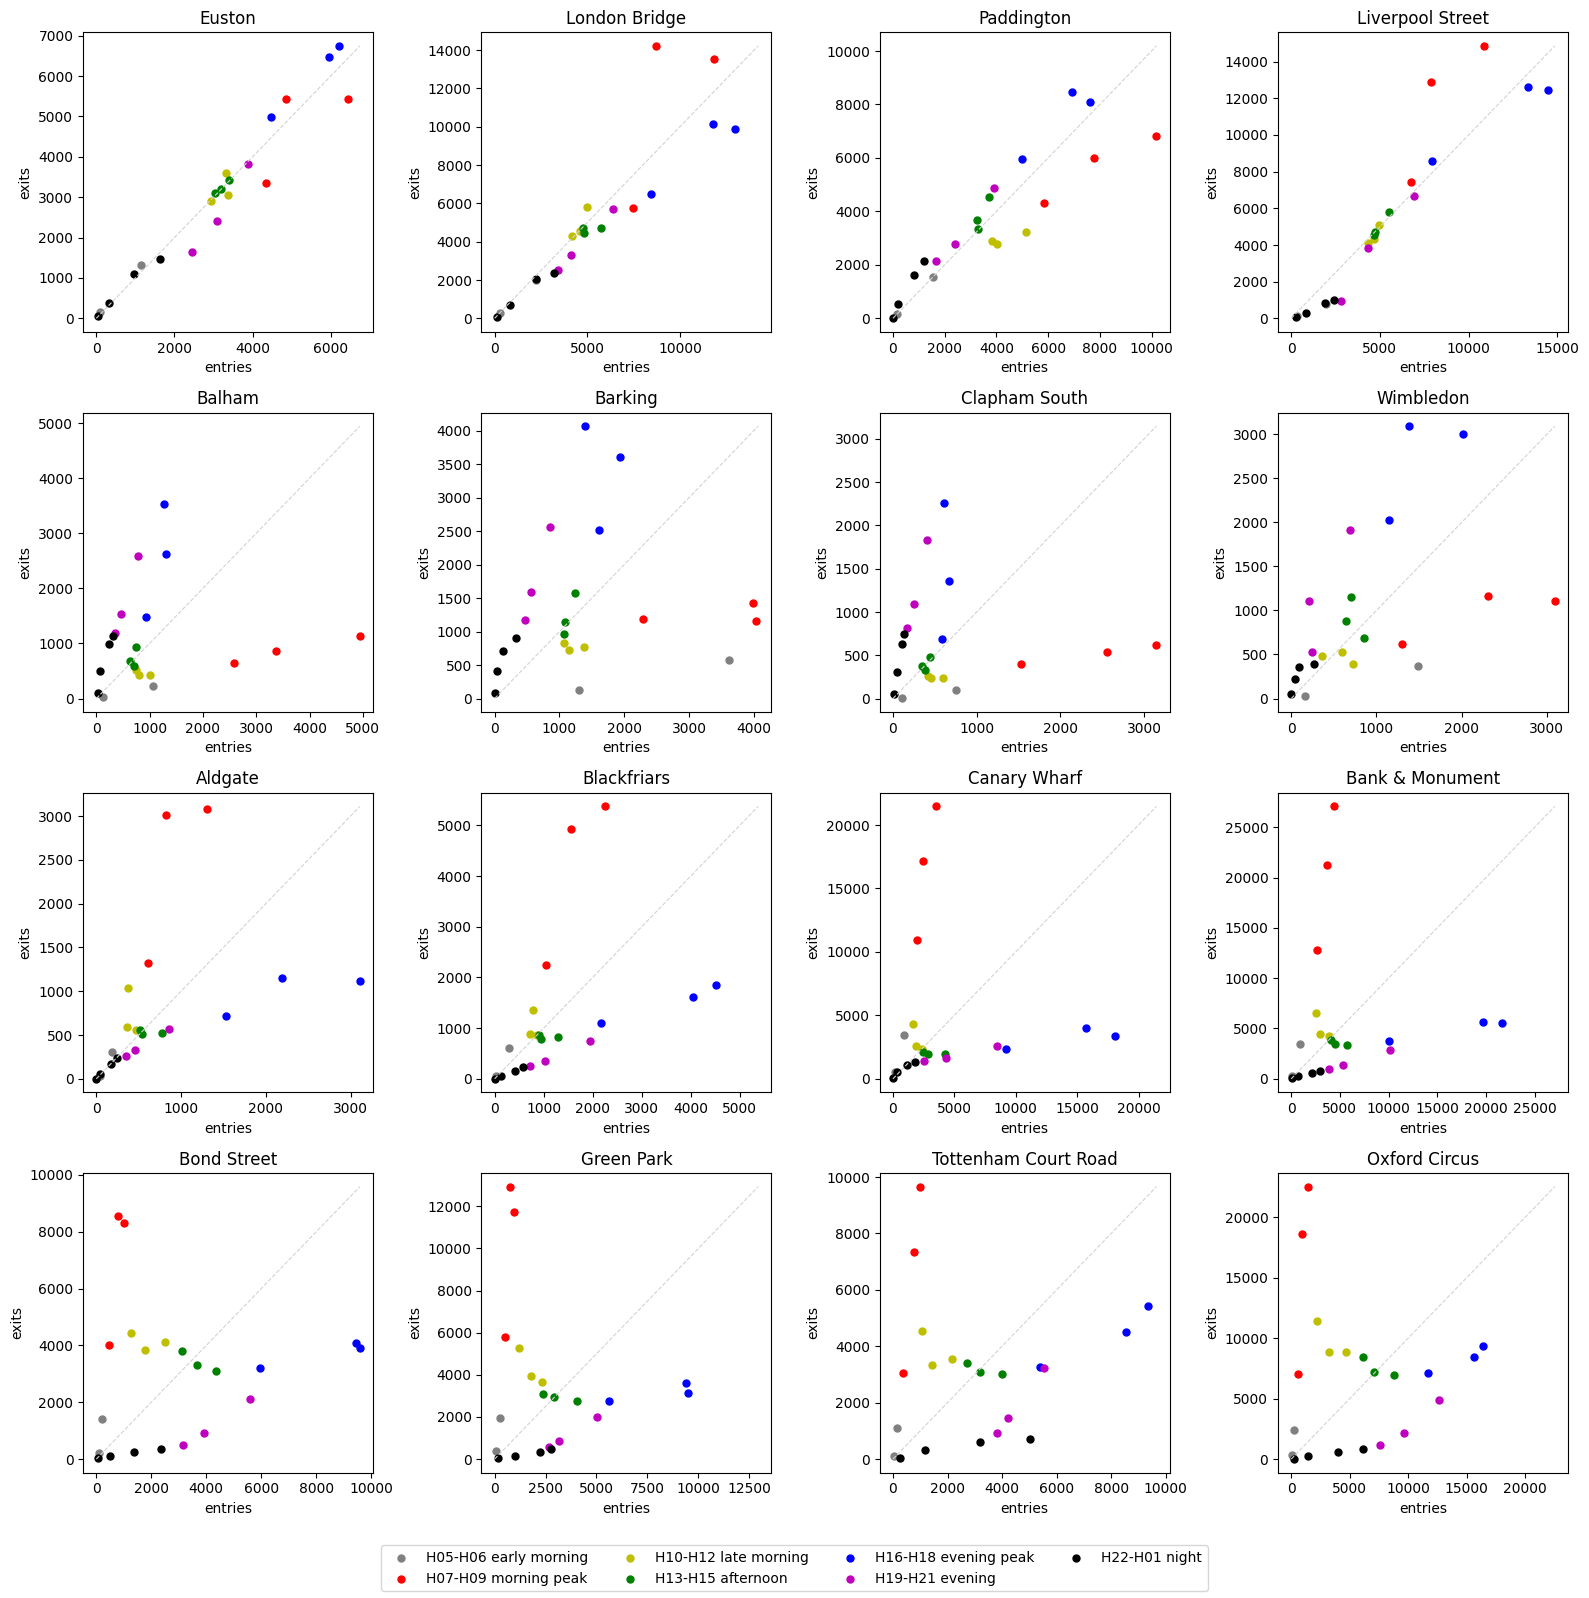

In [12]:
transfer    = ['Euston', 'London Bridge', 'Paddington', 'Liverpool Street']
residential = ['Balham', 'Barking', 'Clapham South', 'Wimbledon']
work        = ['Aldgate', 'Blackfriars', 'Canary Wharf', 'Bank & Monument']
shopping    = ['Bond Street', 'Green Park', 'Tottenham Court Road', 'Oxford Circus']
stations = transfer + residential + work + shopping

HOUR_GROUPS = [
    ("H05-H06 early morning", ['H05', 'H06'], 'gray'),
    ("H07-H09 morning peak",  ['H07', 'H08', 'H09'], 'r'),
    ("H10-H12 late morning",  ['H10', 'H11', 'H12'], 'y'),
    ("H13-H15 afternoon",     ['H13', 'H14', 'H15'], 'g'),
    ("H16-H18 evening peak",  ['H16', 'H17', 'H18'], 'b'),
    ("H19-H21 evening",       ['H19', 'H20', 'H21'], 'm'),
    ("H22-H01 night",         ['H22', 'H23', 'H00', 'H01'], 'k'),
]

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes = axes.flatten()
for station, ax in zip(stations, axes):
    for label, hrs, colour in HOUR_GROUPS:
        ax.scatter(entries.loc[station, hrs], exits.loc[station, hrs],
                   c=colour, s=25, label=label)
    lim = max(entries.loc[station].max(), exits.loc[station].max())
    ax.plot([0, lim], [0, lim], ls='--', lw=0.8, color='lightgray')   # entries = exits
    ax.set_title(station)
    ax.set_xlabel('entries')
    ax.set_ylabel('exits')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4)
fig.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

| Colour | Hours | Description |
|---|---|---|
| Grey | H05–H06 | Early morning |
| Red | H07–H09 | Morning peak |
| Yellow | H10–H12 | Late morning |
| Green | H13–H15 | Afternoon |
| Blue | H16–H18 | Evening peak |
| Magenta | H19–H21 | Evening |
| Black | H22–H01 | Night |


* Interchange stations show a strong positive linear correlation between entries and exits, with points clustered around the line y = x. This suggests balanced passenger flows in both directions throughout the day, possibly due to interchange and mainline connections. However, this remains a hypothesis, as the data cannot distinguish these passengers from other station users.
* Residential stations show the commuter pattern clearly: many entries in the morning peak (red points far right) and many exits in the evening peak (blue points high up).
* Business stations show the mirror image: many exits in the morning peak and many entries in the evening peak.
* Shopping stations follow the business pattern at rush hour but also carry heavy traffic in both directions during the daytime (the yellow and green points sit well above zero on both axes), unlike business stations.

## 4. Limitations
* The data covers one unspecified weekday in 2017, so it says nothing about weekends, seasons or later years.
* Counts come from barriers plus manual counts, and some interchange stations include non-Underground passengers.
* The 16-station comparison uses four hand-picked stations per group, so the group-level statements are qualitative impressions, not statistical results.
* Each station has only 21 points (one per operating hour), and a scatter plot hides their time order; the colours are the only clue.
* Hour labels refer to the start of the hour (H08 means 08:00–08:59).

## 5. What I learned
* A bar chart of counts per category is a distribution, but the usual mean() and median() give wrong answers unless the bars are used as weights.
* When the mean and median differ a lot, the shape of the distribution (here, right-skew) is the story, not the numbers on their own.
* Grouping stations by function turned a pile of scatter plots into a readable comparison, and a legend plus a reference line made the plots self-explanatory.

## 6. Next steps
* Distribution of total daily exits across stations (histogram, probably on a log scale because of the skew).
* Compare the station-level distributions at different times, for example H08 against H18.
* more data
* corellation